# VEPL-Net: Test on Custom Images

This notebook applies the trained vegetation and power line models to custom test images located in `test_few_images/` directory.

## 1. Import Required Libraries

In [11]:
import os
import cv2
import torch
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Segmentation Models PyTorch version: {smp.__version__}")

All libraries imported successfully
PyTorch version: 2.7.1
Segmentation Models PyTorch version: 0.5.0


## 2. Configuration

In [12]:
# Device configuration
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# Paths
TEST_IMAGE_DIR = 'test_few_images'
MODEL_VEG_PATH = '../models/vepl_vegetation_model.pth.tar'
MODEL_PL_PATH = '../models/vepl_powerline_model.pth.tar'

# Model configuration
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

print(f"Test images directory: {TEST_IMAGE_DIR}")
print(f"Vegetation model: {MODEL_VEG_PATH}")
print(f"Power line model: {MODEL_PL_PATH}")

Using device: mps
Test images directory: test_few_images
Vegetation model: ../models/vepl_vegetation_model.pth.tar
Power line model: ../models/vepl_powerline_model.pth.tar


## 3. Load Trained Models

In [13]:
def load_model(path, model_class, encoder_name):
    """
    Load a trained segmentation model from checkpoint.
    
    Args:
        path: Path to model checkpoint
        model_class: Model architecture class (e.g., smp.Unet, smp.DeepLabV3)
        encoder_name: Encoder backbone name (e.g., 'vgg16', 'resnet34')
    
    Returns:
        Loaded model in evaluation mode
    """
    model = model_class(
        encoder_name=encoder_name,
        encoder_weights=None,
        in_channels=3,
        classes=1,
    ).to(DEVICE)
    
    checkpoint = torch.load(path, map_location=DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    
    return model

print("Loading vegetation model (U-Net + VGG16)...")
veg_model = load_model(MODEL_VEG_PATH, smp.Unet, "vgg16")
print("Vegetation model loaded successfully")

print("\nLoading power line model (DeepLabV3 + ResNet34)...")
pl_model = load_model(MODEL_PL_PATH, smp.DeepLabV3, "resnet34")
print("Power line model loaded successfully")

print("\nBoth models ready for inference")

Loading vegetation model (U-Net + VGG16)...
Vegetation model loaded successfully

Loading power line model (DeepLabV3 + ResNet34)...
Power line model loaded successfully

Both models ready for inference


## 4. Data Preprocessing Transform

In [14]:
# Inference transform (same as used during training validation)
transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=[0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0], max_pixel_value=255.0),
    ToTensorV2(),
])

print("Preprocessing transform defined")
print(f"Input size: {IMAGE_HEIGHT}x{IMAGE_WIDTH}")
print("Normalization: mean=[0,0,0], std=[1,1,1]")

Preprocessing transform defined
Input size: 256x256
Normalization: mean=[0,0,0], std=[1,1,1]


## 5. Utility Functions

In [15]:
def create_colored_segmentation(veg_mask, pl_mask, encroachment_mask, image_shape):
    """
    Create a colored segmentation visualization:
    - Vegetation only: Green (0, 255, 0)
    - Power Lines only: Yellow (255, 255, 0)
    - Encroachment/Overlap: Red (255, 0, 0)
    """
    colored_mask = np.zeros((image_shape[0], image_shape[1], 3), dtype=np.uint8)
    
    # Vegetation areas (green)
    vegetation_only = np.logical_and(veg_mask > 0.5, pl_mask <= 0.5)
    colored_mask[vegetation_only] = [0, 255, 0]
    
    # Power line areas (yellow)
    powerline_only = np.logical_and(pl_mask > 0.5, veg_mask <= 0.5)
    colored_mask[powerline_only] = [255, 255, 0]
    
    # Encroachment areas (red) - highest priority
    colored_mask[encroachment_mask > 0] = [255, 0, 0]
    
    return colored_mask

def get_test_images(test_dir, extensions=['.png', '.jpg', '.jpeg', '.tif', '.tiff']):
    """
    Get all image files from test directory.
    
    Args:
        test_dir: Directory containing test images
        extensions: List of valid image extensions
    
    Returns:
        List of image file paths
    """
    image_paths = []
    test_path = Path(test_dir)
    
    if not test_path.exists():
        print(f"Test directory does not exist: {test_dir}")
        return image_paths
    
    for ext in extensions:
        image_paths.extend(test_path.glob(f"*{ext}"))
        image_paths.extend(test_path.glob(f"*{ext.upper()}"))
    
    image_paths = sorted([str(p) for p in image_paths])
    return image_paths

print("Utility functions defined successfully")

Utility functions defined successfully


## 6. Single Image Prediction Function

In [16]:
def predict_single_image(image_path, save_output=False, output_dir='output'):
    """
    Predict vegetation, power lines, and encroachment for a single image.
    
    Args:
        image_path: Path to input image
        save_output: Whether to save the output visualization
        output_dir: Directory to save outputs
    
    Returns:
        Dictionary with predictions and statistics
    """
    # Load and preprocess image
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        print(f"Could not load image: {image_path}")
        return None
    
    original_shape = image_bgr.shape[:2]
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    
    # Apply preprocessing
    augmented = transform(image=image_rgb)
    input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)
    
    # Get predictions from both models
    with torch.no_grad():
        pred_veg = torch.sigmoid(veg_model(input_tensor))
        pred_pl = torch.sigmoid(pl_model(input_tensor))
        
        # Convert to numpy
        pred_veg_np = pred_veg.squeeze(0).squeeze(0).cpu().numpy()
        pred_pl_np = pred_pl.squeeze(0).squeeze(0).cpu().numpy()
    
    # Resize predictions back to original image size
    pred_veg_resized = cv2.resize(pred_veg_np, (original_shape[1], original_shape[0]), interpolation=cv2.INTER_LINEAR)
    pred_pl_resized = cv2.resize(pred_pl_np, (original_shape[1], original_shape[0]), interpolation=cv2.INTER_LINEAR)
    
    # Create binary masks (threshold at 0.5)
    veg_binary = (pred_veg_resized > 0.5).astype(np.float32)
    pl_binary = (pred_pl_resized > 0.5).astype(np.float32)
    
    # Create encroachment mask (intersection)
    encroachment_mask = np.logical_and(veg_binary, pl_binary).astype(np.uint8)
    
    # Calculate statistics
    total_pixels = veg_binary.shape[0] * veg_binary.shape[1]
    veg_pixels = np.sum(veg_binary)
    pl_pixels = np.sum(pl_binary)
    encroach_pixels = np.sum(encroachment_mask)
    
    veg_percent = (veg_pixels / total_pixels) * 100
    pl_percent = (pl_pixels / total_pixels) * 100
    encroach_percent = (encroach_pixels / total_pixels) * 100
    
    # Create colored visualization (now matches original image size)
    colored_pred = create_colored_segmentation(
        veg_binary, pl_binary, encroachment_mask, image_rgb.shape
    )
    
    # Visualization
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Original image
    axes[0, 0].imshow(image_rgb)
    axes[0, 0].set_title(f"Original Image\n{Path(image_path).name}", fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Vegetation prediction
    axes[0, 1].imshow(image_rgb)
    axes[0, 1].imshow(veg_binary, cmap='Greens', alpha=0.6)
    axes[0, 1].set_title(f"Vegetation Prediction\nPixels: {veg_pixels:,.0f} ({veg_percent:.1f}%)", 
                        fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Power line prediction
    axes[1, 0].imshow(image_rgb)
    axes[1, 0].imshow(pl_binary, cmap='YlOrBr', alpha=0.6)
    axes[1, 0].set_title(f"Power Line Prediction\nPixels: {pl_pixels:,.0f} ({pl_percent:.1f}%)", 
                        fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    
    # Combined prediction with encroachment
    axes[1, 1].imshow(image_rgb)
    axes[1, 1].imshow(colored_pred, alpha=0.6)
    axes[1, 1].set_title(f"Combined Segmentation\nEncroachment: {encroach_pixels:,.0f} pixels ({encroach_percent:.1f}%)", 
                        fontsize=14, fontweight='bold')
    axes[1, 1].axis('off')
    
    plt.suptitle('VEPL-Net Prediction Results\nGreen=Vegetation | Yellow=Power Lines | Red=Encroachment', 
                fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    
    # Save output if requested
    if save_output:
        os.makedirs(output_dir, exist_ok=True)
        output_name = Path(image_path).stem + '_prediction.png'
        output_path = os.path.join(output_dir, output_name)
        plt.savefig(output_path, dpi=150, bbox_inches='tight')
        print(f"Saved output to: {output_path}")
    
    plt.show()
    
    # Return results
    return {
        'image_path': image_path,
        'veg_pixels': veg_pixels,
        'pl_pixels': pl_pixels,
        'encroach_pixels': encroach_pixels,
        'veg_percent': veg_percent,
        'pl_percent': pl_percent,
        'encroach_percent': encroach_percent,
        'pred_veg': pred_veg_resized,
        'pred_pl': pred_pl_resized,
        'encroachment_mask': encroachment_mask
    }

print("Single image prediction function defined")

Single image prediction function defined


## 7. Batch Prediction Function

In [17]:
def predict_batch(image_paths, max_display=8):
    """
    Predict on multiple images and display in a grid.
    
    Args:
        image_paths: List of image file paths
        max_display: Maximum number of images to display
    """
    num_images = min(len(image_paths), max_display)
    
    if num_images == 0:
        print("No images to process")
        return
    
    # Layout: 3 rows per image (original, predictions, combined)
    cols = min(4, num_images)
    rows_per_image = 3
    sets = (num_images + cols - 1) // cols
    total_rows = rows_per_image * sets
    
    fig, axes = plt.subplots(total_rows, cols, figsize=(cols * 5, total_rows * 4))
    
    # Handle single image case
    if num_images == 1:
        axes = axes.reshape(-1, 1)
    elif total_rows == rows_per_image:
        axes = axes.reshape(rows_per_image, -1)
    
    results = []
    
    for i, image_path in enumerate(image_paths[:num_images]):
        # Calculate position in grid
        set_idx = i // cols
        col = i % cols
        row_offset = set_idx * rows_per_image
        
        try:
            # Load and process image
            image_bgr = cv2.imread(image_path)
            if image_bgr is None:
                print(f"Could not load: {image_path}")
                continue
            
            original_shape = image_bgr.shape[:2]
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            
            # Apply transform
            augmented = transform(image=image_rgb)
            input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)
            
            # Get predictions
            with torch.no_grad():
                pred_veg = torch.sigmoid(veg_model(input_tensor))
                pred_pl = torch.sigmoid(pl_model(input_tensor))
                
                pred_veg_np = pred_veg.squeeze(0).squeeze(0).cpu().numpy()
                pred_pl_np = pred_pl.squeeze(0).squeeze(0).cpu().numpy()
            
            # Resize predictions back to original image size
            pred_veg_resized = cv2.resize(pred_veg_np, (original_shape[1], original_shape[0]), interpolation=cv2.INTER_LINEAR)
            pred_pl_resized = cv2.resize(pred_pl_np, (original_shape[1], original_shape[0]), interpolation=cv2.INTER_LINEAR)
            
            # Create masks
            veg_binary = (pred_veg_resized > 0.5).astype(np.float32)
            pl_binary = (pred_pl_resized > 0.5).astype(np.float32)
            encroachment_mask = np.logical_and(veg_binary, pl_binary).astype(np.uint8)
            
            # Calculate statistics
            veg_pixels = np.sum(veg_binary)
            pl_pixels = np.sum(pl_binary)
            encroach_pixels = np.sum(encroachment_mask)
            
            # Create colored visualization (now matches original image size)
            colored_pred = create_colored_segmentation(
                veg_binary, pl_binary, encroachment_mask, image_rgb.shape
            )
            
            # Row 1: Original image
            axes[row_offset + 0, col].imshow(image_rgb)
            axes[row_offset + 0, col].set_title(f"{Path(image_path).name}", 
                                               fontsize=10, fontweight='bold')
            axes[row_offset + 0, col].axis('off')
            
            # Row 2: Model predictions colored
            axes[row_offset + 1, col].imshow(colored_pred)
            axes[row_offset + 1, col].set_title(f"V:{veg_pixels:,.0f} P:{pl_pixels:,.0f} E:{encroach_pixels:,.0f}",
                                               fontsize=10, fontweight='bold')
            axes[row_offset + 1, col].axis('off')
            
            # Row 3: Overlay on original
            axes[row_offset + 2, col].imshow(image_rgb)
            axes[row_offset + 2, col].imshow(colored_pred, alpha=0.5)
            axes[row_offset + 2, col].set_title("Overlay", fontsize=10, fontweight='bold')
            axes[row_offset + 2, col].axis('off')
            
            results.append({
                'image': Path(image_path).name,
                'veg_pixels': veg_pixels,
                'pl_pixels': pl_pixels,
                'encroach_pixels': encroach_pixels
            })
            
            print(f"Processed {Path(image_path).name}: V={veg_pixels:,.0f}, P={pl_pixels:,.0f}, E={encroach_pixels:,.0f}")
            
        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            continue
    
    # Hide unused subplots
    for i in range(num_images, (total_rows // rows_per_image) * cols):
        col = i % cols
        set_idx = i // cols
        row_offset = set_idx * rows_per_image
        
        for row in range(rows_per_image):
            if row_offset + row < total_rows:
                axes[row_offset + row, col].axis('off')
    
    plt.suptitle('VEPL-Net Batch Predictions\nGreen=Vegetation | Yellow=Power Lines | Red=Encroachment',
                fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
    
    return results

print("Batch prediction function defined")

Batch prediction function defined


## 8. Load and Process Test Images

In [18]:
# Get all test images from the test_few_images directory
print(f"Looking for images in: {TEST_IMAGE_DIR}")
test_images = get_test_images(TEST_IMAGE_DIR)

print(f"\nFound {len(test_images)} test images:")
for i, img_path in enumerate(test_images, 1):
    print(f"  {i}. {Path(img_path).name}")

if len(test_images) == 0:
    print(f"\nNo images found in {TEST_IMAGE_DIR}/")
    print("Please add some images to test on.")
    print("Supported formats: .png, .jpg, .jpeg, .tif, .tiff")

Looking for images in: test_few_images

Found 4 test images:
  1. 12_det_img_50.jpg
  2. 133_det_img_2230.jpg
  3. 266_det_img_90.jpg
  4. 804_det_img_120.jpg


## 9. Run Predictions

Choose one of the following cells to run:
- **Option A**: Process all images in batch
- **Option B**: Process a single specific image

### Option A: Batch Processing (All Images)

Processing 4 images...

Processed 12_det_img_50.jpg: V=5,016, P=0, E=0
Processed 133_det_img_2230.jpg: V=0, P=0, E=0
Processed 266_det_img_90.jpg: V=0, P=0, E=0
Processed 804_det_img_120.jpg: V=0, P=0, E=0


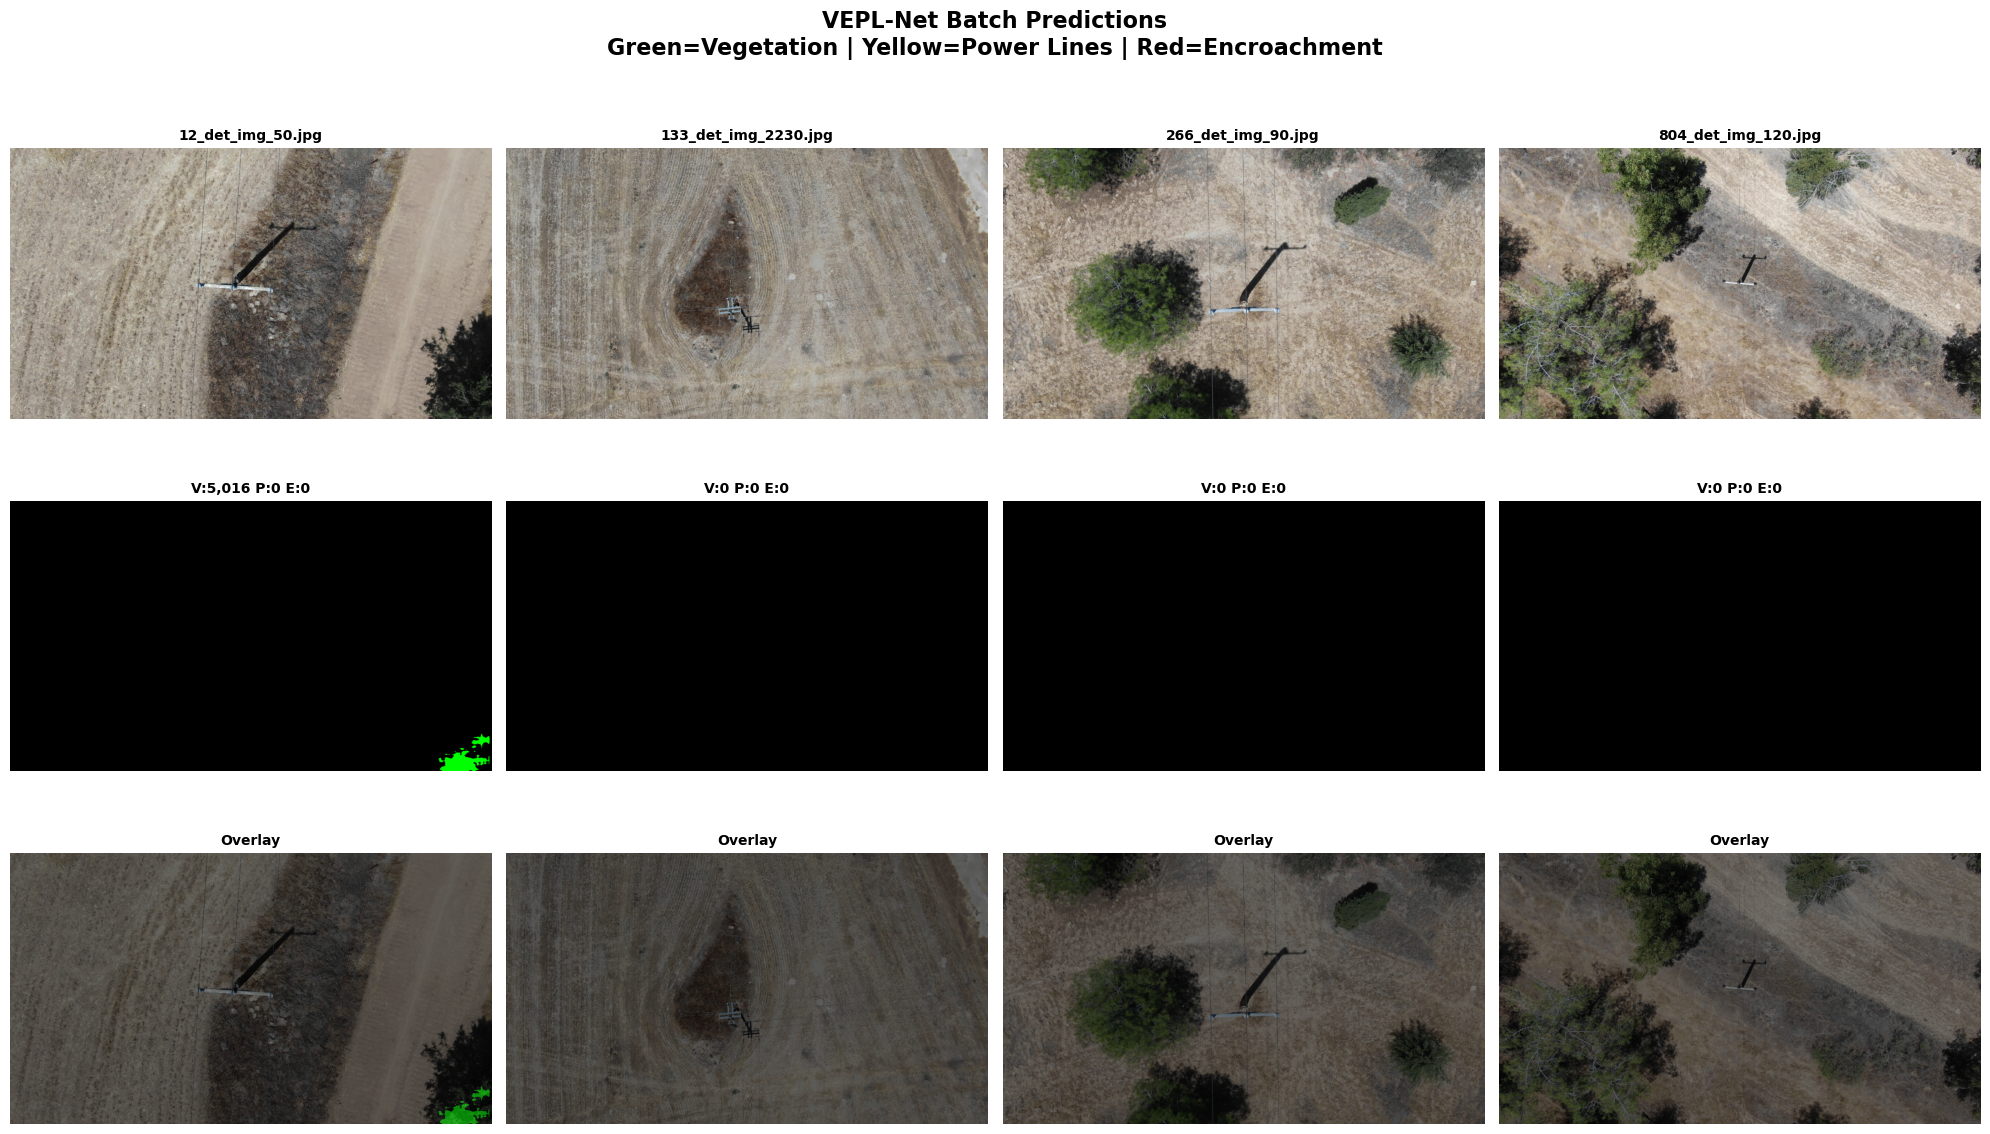


Batch processing completed!

Summary Statistics:
12_det_img_50.jpg              | V:   5,016 | P:       0 | E:       0
133_det_img_2230.jpg           | V:       0 | P:       0 | E:       0
266_det_img_90.jpg             | V:       0 | P:       0 | E:       0
804_det_img_120.jpg            | V:       0 | P:       0 | E:       0


In [19]:
# Process all test images in batch
if len(test_images) > 0:
    print(f"Processing {len(test_images)} images...\n")
    batch_results = predict_batch(test_images, max_display=8)
    
    print("\nBatch processing completed!")
    print("\nSummary Statistics:")
    print("="*60)
    for result in batch_results:
        print(f"{result['image']:30s} | V:{result['veg_pixels']:8,.0f} | P:{result['pl_pixels']:8,.0f} | E:{result['encroach_pixels']:8,.0f}")
else:
    print("No images to process")

### Option B: Single Image Processing

Processing single image: 12_det_img_50.jpg



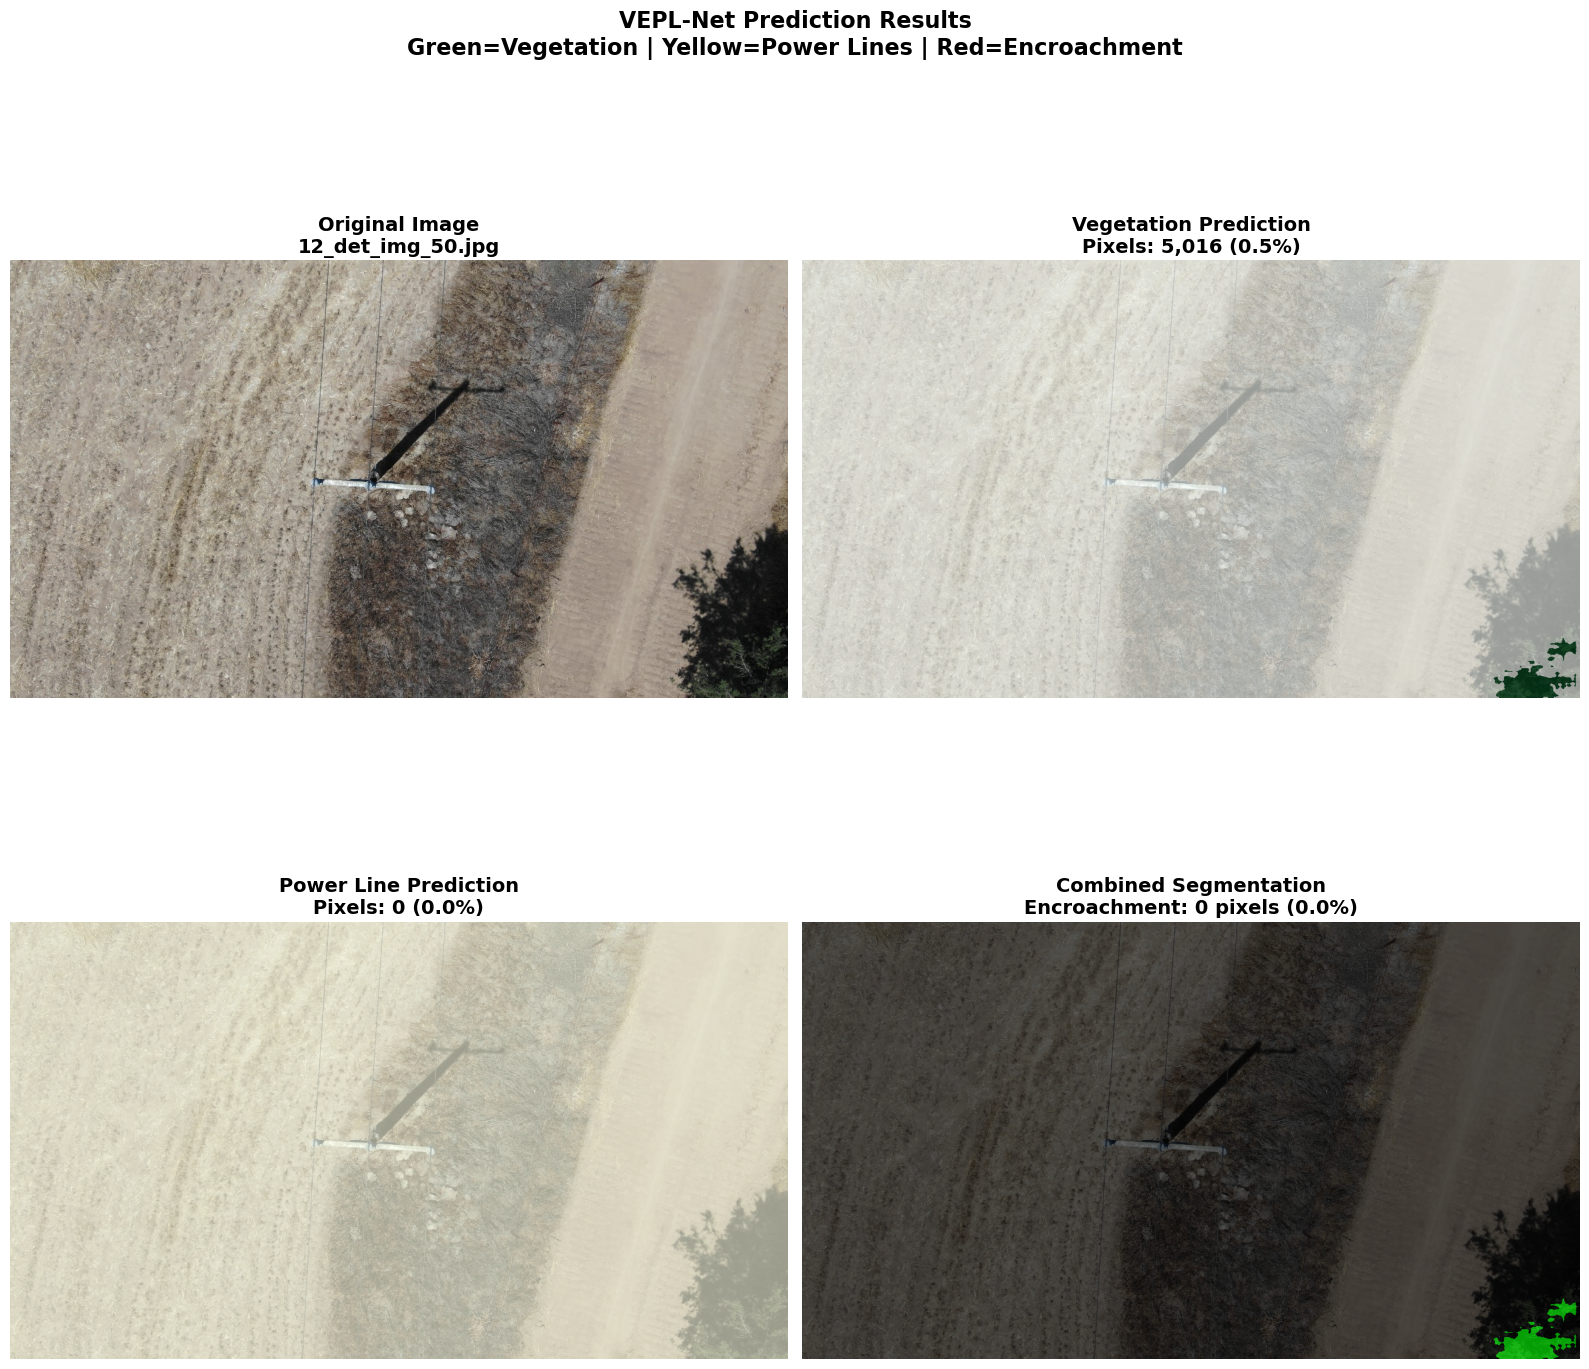


Detailed Results:
Image: 12_det_img_50.jpg
Vegetation pixels: 5,016 (0.54%)
Power line pixels: 0 (0.00%)
Encroachment pixels: 0 (0.00%)


In [20]:
# Process a single image (change index or path as needed)
if len(test_images) > 0:
    # Process the first image (change index to process different images)
    single_image_path = test_images[0]
    
    print(f"Processing single image: {Path(single_image_path).name}\n")
    result = predict_single_image(single_image_path, save_output=False)
    
    if result:
        print("\nDetailed Results:")
        print("="*60)
        print(f"Image: {Path(result['image_path']).name}")
        print(f"Vegetation pixels: {result['veg_pixels']:,.0f} ({result['veg_percent']:.2f}%)")
        print(f"Power line pixels: {result['pl_pixels']:,.0f} ({result['pl_percent']:.2f}%)")
        print(f"Encroachment pixels: {result['encroach_pixels']:,.0f} ({result['encroach_percent']:.2f}%)")
else:
    print("No images to process")

## 10. Save Predictions (Optional)

Uncomment and run this cell to save predictions to disk.

In [21]:
# # Save predictions for all test images
# output_dir = 'output_predictions'
# os.makedirs(output_dir, exist_ok=True)
# 
# print(f"Saving predictions to: {output_dir}/")
# 
# for img_path in test_images:
#     result = predict_single_image(img_path, save_output=True, output_dir=output_dir)
#     if result:
#         print(f"Saved: {Path(img_path).stem}_prediction.png")
# 
# print(f"\nAll predictions saved to: {output_dir}/")